# COVID-19 Exploratory Data Analysis
**Author:** Saim Patel

## 1. Load the data

In [ ]:
import pandas as pd
from pathlib import Path

# Local repo path first; falls back to a file uploaded to Colab
path = Path("../data/COVID-19 Coronavirus.csv")
if not path.exists():
    path = Path("/content/COVID-19 Coronavirus.csv")

df6 = pd.read_csv(path)
df6

## 2. Inspect the data

In [ ]:
df6.shape

(225, 10)

In [ ]:
df6.head(5)

,Country,Other names,ISO 3166-1 alpha-3 CODE,Population,Continent,Total Cases,Total Deaths,Tot Cases//1M pop,Tot Deaths/1M pop,Death percentage
0,Afghanistan,Afghanistan,AFG,40462186,Asia,177827,7671,4395,190,4.313743
1,Albania,Albania,ALB,2872296,Europe,273870,3492,95349,1216,1.275058
2,Algeria,Algeria,DZA,45236699,Africa,265691,6874,5873,152,2.587216
3,Andorra,Andorra,AND,77481,Europe,40024,153,516565,1975,0.382271
4,Angola,Angola,AGO,34654212,Africa,99194,1900,2862,55,1.915438


In [ ]:
df6.tail(5)

,Country,Other names,ISO 3166-1 alpha-3 CODE,Population,Continent,Total Cases,Total Deaths,Tot Cases//1M pop,Tot Deaths/1M pop,Death percentage
220,Wallis and Futuna,Wallis and Futuna Islands,WLF,10894,Oceania,454,7,41674,643,1.541850
221,Western Sahara,Western Sahara,ESHÂ,623031,Africa,10,1,16,2,10.000000
222,Yemen,Yemen,YEM,30975258,Asia,11806,2143,381,69,18.151787
223,Zambia,Zambia,ZMB,19284482,Africa,317076,3967,16442,206,1.251120
224,Zimbabwe,Zimbabwe,ZWE,15241601,Africa,246525,5446,16174,357,2.209107


In [ ]:
df6.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 225 entries, 0 to 224
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Country                  225 non-null    object 
 1   Other names              224 non-null    object 
 2   ISO 3166-1 alpha-3 CODE  225 non-null    object 
 3   Population               225 non-null    int64  
 4   Continent                225 non-null    object 
 5   Total Cases              225 non-null    int64  
 6   Total Deaths             225 non-null    int64  
 7   Tot Cases//1M pop        225 non-null    int64  
 8   Tot Deaths/1M pop        225 non-null    int64  
 9   Death percentage         225 non-null    float64
dtypes: float64(1), int64(5), object(4)
memory usage: 17.7+ KB


## 3. Clean the data

In [ ]:
df6.isnull()

,Country,Other names,ISO 3166-1 alpha-3 CODE,Population,Continent,Total Cases,Total Deaths,Tot Cases//1M pop,Tot Deaths/1M pop,Death percentage
0,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...
220,False,False,False,False,False,False,False,False,False,False
221,False,False,False,False,False,False,False,False,False,False
222,False,False,False,False,False,False,False,False,False,False
223,False,False,False,False,False,False,False,False,False,False


In [ ]:
df6[df6.isna().any(axis=1)]

,Country,Other names,ISO 3166-1 alpha-3 CODE,Population,Continent,Total Cases,Total Deaths,Tot Cases//1M pop,Tot Deaths/1M pop,Death percentage
135,Montenegro,NaN,MNE,628205,Europe,233326,2705,371417,4306,1.159322


In [ ]:
# 'Other names' has one missing value; fill it with the country name
df6['Other names'] = df6['Other names'].fillna(df6['Country'])

In [ ]:
df6.iloc[135]

In [ ]:
df6.describe()

,Population,Total Cases,Total Deaths,Tot Cases//1M pop,Tot Deaths/1M pop,Death percentage
count,2.250000e+02,2.250000e+02,2.250000e+02,225.000000,225.000000,225.000000
mean,3.507321e+07,2.184781e+06,2.744813e+04,136900.373333,1096.715556,1.444125
std,1.392418e+08,7.275938e+06,9.689177e+04,145060.340289,1195.715543,1.741728
min,8.050000e+02,1.000000e+00,0.000000e+00,9.000000,0.000000,0.000000
25%,5.665570e+05,2.407100e+04,1.890000e+02,11384.000000,123.000000,0.511291
50%,5.827911e+06,1.639360e+05,1.965000e+03,88987.000000,708.000000,1.036905
75%,2.190585e+07,1.092547e+06,1.366000e+04,223335.000000,1795.000000,1.977017
max,1.439324e+09,8.183905e+07,1.008222e+06,696044.000000,6286.000000,18.151787


In [ ]:
df6.rename(columns={'ISO 3166-1 alpha-3 CODE': 'Iso_Code'}, inplace=True)

df6.head(4)

,Country,Other names,Iso_Code,Population,Continent,Total Cases,Total Deaths,Tot Cases//1M pop,Tot Deaths/1M pop,Death percentage
0,Afghanistan,Afghanistan,AFG,40462186,Asia,177827,7671,4395,190,4.313743
1,Albania,Albania,ALB,2872296,Europe,273870,3492,95349,1216,1.275058
2,Algeria,Algeria,DZA,45236699,Africa,265691,6874,5873,152,2.587216
3,Andorra,Andorra,AND,77481,Europe,40024,153,516565,1975,0.382271


## 4. Cases by country

In [ ]:
df6.nlargest(5, 'Total Cases')[['Country', 'Total Cases']]

,Country,Total Cases
214,USA,81839052
92,India,43029044
26,Brazil,29999816
70,France,25997852
76,Germany,21646375


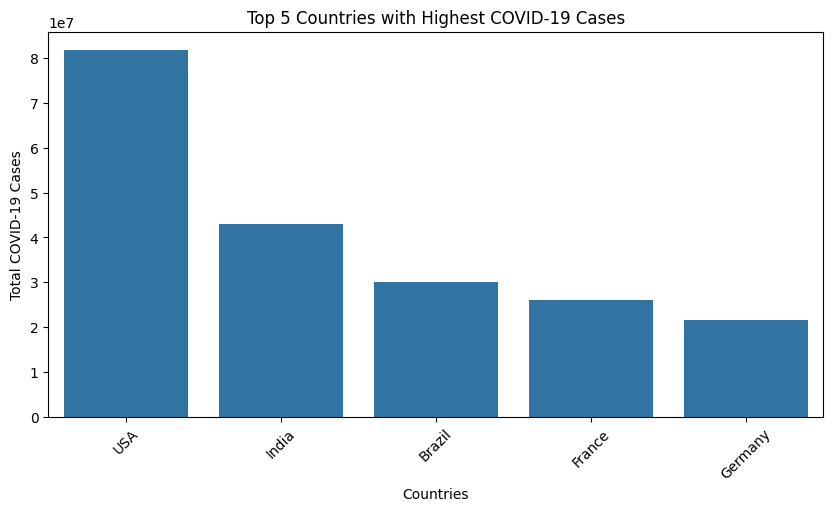

In [ ]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
top = df6.nlargest(5, 'Total Cases')

plt.figure(figsize=(10, 5))

sns.barplot(data=top, x='Country', y='Total Cases')

plt.title('Top 5 Countries with Highest COVID-19 Cases')
plt.xlabel('Countries')
plt.ylabel('Total COVID-19 Cases')
plt.xticks(rotation=45)

plt.show()

In [ ]:
display(df6.nsmallest(5, 'Total Cases')[['Country', 'Total Cases']])

,Country,Total Cases
131,Micronesia,1
168,Saint Helena,2
125,Marshall Islands,7
148,Niue,7
221,Western Sahara,10


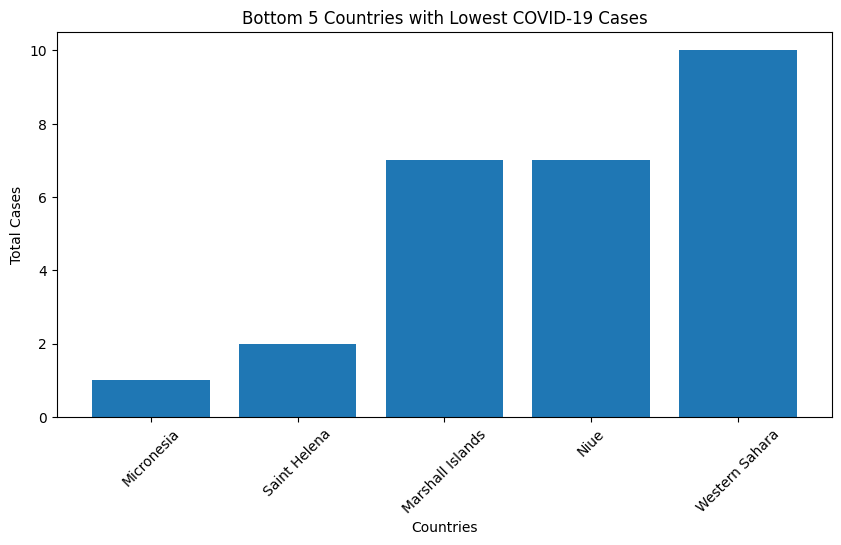

In [ ]:
low = df6.sort_values('Total Cases').head(5)

plt.figure(figsize=(10,5))
plt.bar(low['Country'], low['Total Cases'])

plt.title('Bottom 5 Countries with Lowest COVID-19 Cases')
plt.xlabel('Countries')
plt.ylabel('Total Cases')
plt.xticks(rotation=45)
plt.show()

## 5. Deaths by country

In [ ]:
deaths = df6.sort_values('Total Deaths', ascending=False).head(5)
deaths[['Country', 'Total Deaths']]

,Country,Total Deaths
214,USA,1008222
26,Brazil,660269
92,India,521388
165,Russia,369708
130,Mexico,323212


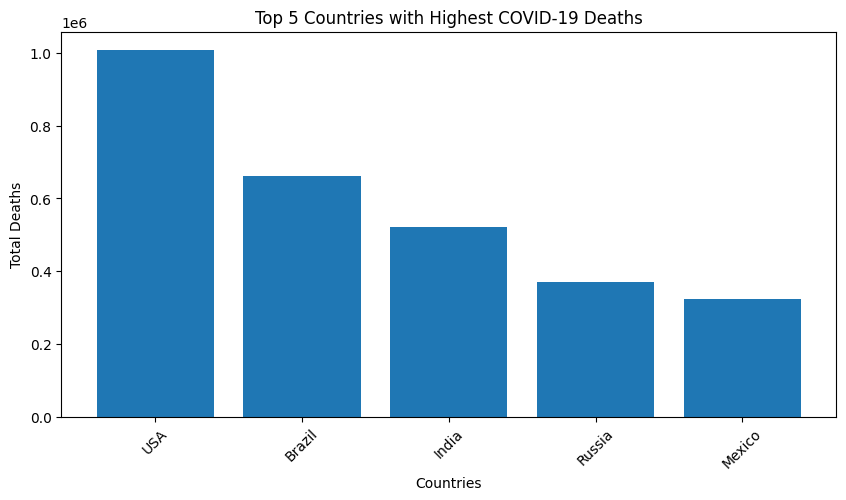

In [ ]:
top_deaths = df6.sort_values('Total Deaths', ascending=False).head(5)

plt.figure(figsize=(10,5))
plt.bar(top_deaths['Country'], top_deaths['Total Deaths'])

plt.title('Top 5 Countries with Highest COVID-19 Deaths')
plt.xlabel('Countries')
plt.ylabel('Total Deaths')
plt.xticks(rotation=45)
plt.show()

In [ ]:
low = df6.sort_values('Total Deaths').head(5)
low[['Country', 'Total Deaths']]

,Country,Total Deaths
46,Cook Islands,0
118,Macao,0
125,Marshall Islands,0
67,Falkland Islands,0
217,Vatican City,0


## 6. Death percentage
Deaths as a share of reported cases. Very small case counts can make this value misleading.

In [ ]:
# Recalculate the existing column instead of adding a duplicate
df6['Death percentage'] = (df6['Total Deaths'] / df6['Total Cases']) * 100

In [ ]:
top_percentage = df6.sort_values('Death percentage', ascending=False).head(5)

plt.figure(figsize=(10,5))
plt.bar(top_percentage['Country'], top_percentage['Death percentage'])

plt.title('Top 5 Countries with Highest COVID-19 Death Percentage')
plt.xlabel('Countries')
plt.ylabel('Death Percentage (%)')
plt.xticks(rotation=45)
plt.show()

## 7. Cases by continent

In [ ]:
cases = df6.groupby('Continent')['Total Cases'].sum()

print(cases)

Continent
Africa                              11764207
Asia                               140957179
Europe                             180332483
Latin America and the Caribbean     67509231
Northern America                    85364770
Oceania                              5647957
Name: Total Cases, dtype: int64


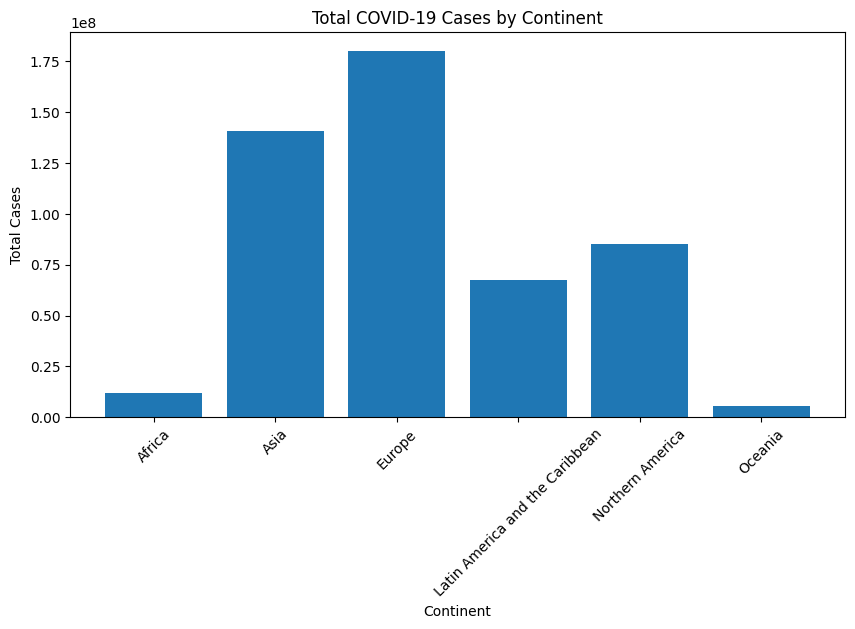

In [ ]:
cases = df6.groupby('Continent')['Total Cases'].sum().reset_index()

plt.figure(figsize=(10,5))

plt.bar(cases['Continent'], cases['Total Cases'])

plt.title('Total COVID-19 Cases by Continent')
plt.xlabel('Continent')
plt.ylabel('Total Cases')
plt.xticks(rotation=45)

plt.show()

## 8. Relationships

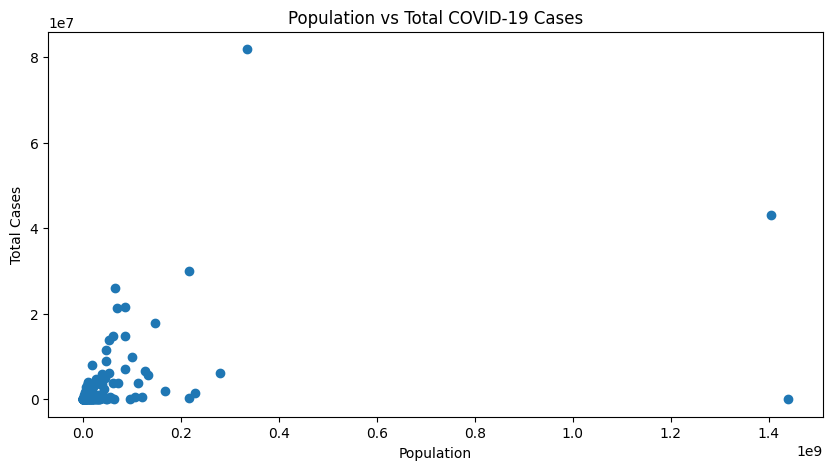

In [ ]:
plt.figure(figsize=(10,5))

plt.scatter(df6['Population'], df6['Total Cases'])

plt.title('Population vs Total COVID-19 Cases')
plt.xlabel('Population')
plt.ylabel('Total Cases')

plt.show()

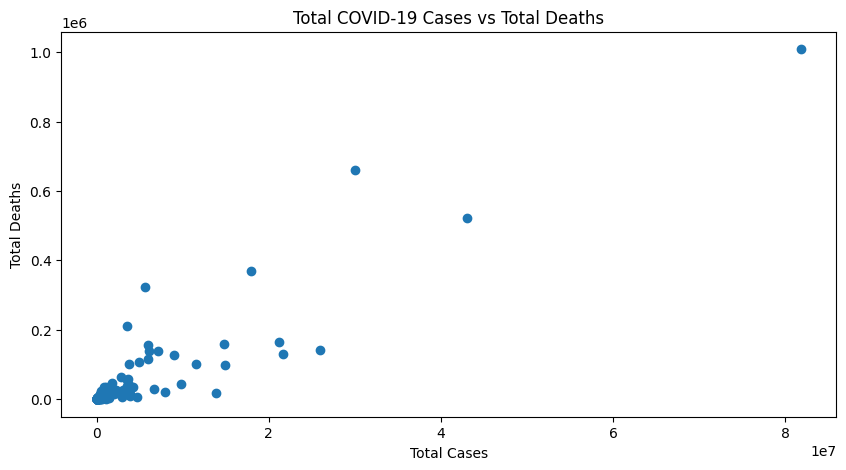

In [ ]:
plt.figure(figsize=(10,5))

plt.scatter(df6['Total Cases'], df6['Total Deaths'])

plt.title('Total COVID-19 Cases vs Total Deaths')
plt.xlabel('Total Cases')
plt.ylabel('Total Deaths')

plt.show()

## 9. Correlation
Spearman rank correlation. Correlation does not imply causation.

In [ ]:
correlation = df6.select_dtypes(include='number').corr(method='spearman')

print(correlation)
plt.figure(figsize=(12,8))

sns.heatmap(correlation, annot=True, cmap='coolwarm')

plt.title('Spearman Correlation Heatmap')

plt.show()